In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('human_vital_signs_dataset_2024.csv')

# Display the first 5 rows to verify the exact column names
display(df.head())

,Patient ID,Heart Rate,Respiratory Rate,Timestamp,Body Temperature,Oxygen Saturation,Systolic Blood Pressure,Diastolic Blood Pressure,Age,Gender,Weight (kg),Height (m),Derived_HRV,Derived_Pulse_Pressure,Derived_BMI,Derived_MAP,Risk Category
0,1,60,12,2024-07-19 21:53:45.729841,36.861707,95.702046,124,86,37,Female,91.541618,1.679351,0.121033,38,32.459031,98.666667,High Risk
1,2,63,18,2024-07-19 21:52:45.729841,36.511633,96.689413,126,84,77,Male,50.704921,1.992546,0.117062,42,12.771246,98.000000,High Risk
2,3,63,15,2024-07-19 21:51:45.729841,37.052049,98.508265,131,78,68,Female,90.316760,1.770228,0.053200,53,28.821069,95.666667,Low Risk
3,4,99,16,2024-07-19 21:50:45.729841,36.654748,95.011801,118,72,41,Female,96.006188,1.833629,0.064475,46,28.554611,87.333333,High Risk
4,5,69,16,2024-07-19 21:49:45.729841,36.975098,98.623792,138,76,25,Female,56.020006,1.866419,0.118484,62,16.081438,96.666667,High Risk


Filtered for Low Risk: 94905 rows remaining out of 200020 total.


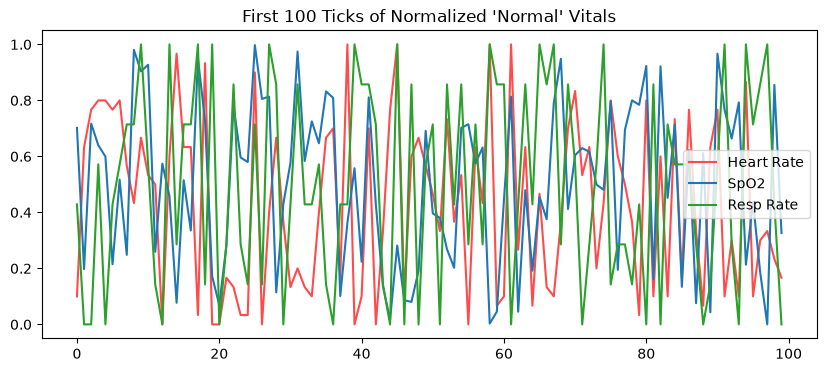

Created 94895 overlapping 10-second sliding windows.
Batch Tensor Shape: torch.Size([32, 10, 4]) -> (Batch_Size, Sequence_Length, Features)


In [4]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# 1. Filter for healthy baseline data
normal_df = df[df['Risk Category'] == 'Low Risk'].copy()
print(f"Filtered for Low Risk: {len(normal_df)} rows remaining out of {len(df)} total.")

# 2. Extract the core columns PLUS Age
features = ['Heart Rate', 'Oxygen Saturation', 'Respiratory Rate', 'Age']
data_array = normal_df[features].values.astype(np.float32)

# 3. Normalize the data (Scale between 0 and 1 for the Neural Network)
min_val = np.min(data_array, axis=0)
max_val = np.max(data_array, axis=0)
normalized_data = (data_array - min_val) / (max_val - min_val + 1e-8)

# 4. Graph the temporal waves (Ignoring Age in the plot since it's a flat line)
plt.figure(figsize=(10, 4))
plt.plot(normalized_data[:100, 0], label='Heart Rate', color='#ff4b4b')
plt.plot(normalized_data[:100, 1], label='SpO2', color='#1f77b4')
plt.plot(normalized_data[:100, 2], label='Resp Rate', color='#2ca02c')
plt.title("First 100 Ticks of Normalized 'Normal' Vitals")
plt.legend()
plt.show()

# 5. The PyTorch Sliding Window Pipeline
class VitalsDataset(Dataset):
    def __init__(self, data, sequence_length=10):
        self.data = data
        self.sequence_length = sequence_length

    def __len__(self):
        return len(self.data) - self.sequence_length

    def __getitem__(self, index):
        window = self.data[index : index + self.sequence_length]
        return torch.tensor(window)

# Initialize the DataLoader 
dataset = VitalsDataset(normalized_data, sequence_length=10)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

print(f"Created {len(dataset)} overlapping 10-second sliding windows.")
for batch in dataloader:
    print(f"Batch Tensor Shape: {batch.shape} -> (Batch_Size, Sequence_Length, Features)")
    break

In [6]:
import torch.nn as nn

class TelemetryLSTMAutoencoder(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=16, num_layers=2):
        super(TelemetryLSTMAutoencoder, self).__init__()
        
        # Encoder: Compresses the 10-step temporal window into latent states
        self.encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Decoder: Reconstructs the 10-step sequence from the bottleneck state
        self.decoder = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        
        # Output projection back to 4 features
        self.output_layer = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        # x shape: (batch_size, seq_len, features) -> (32, 10, 4)
        _, (hidden, _) = self.encoder(x)
        
        # Repeat the final layer's hidden vector across the sequence timeline
        seq_len = x.size(1)
        hidden_repeated = hidden[-1].unsqueeze(1).repeat(1, seq_len, 1)
        
        decoded_output, _ = self.decoder(hidden_repeated)
        reconstructed = self.output_layer(decoded_output)
        return reconstructed

# Instantiate model
model = TelemetryLSTMAutoencoder(input_dim=4, hidden_dim=16, num_layers=2)
print(model)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {trainable_params}")

TelemetryLSTMAutoencoder(
  (encoder): LSTM(4, 16, num_layers=2, batch_first=True)
  (decoder): LSTM(16, 16, num_layers=2, batch_first=True)
  (output_layer): Linear(in_features=16, out_features=4, bias=True)
)

Total Trainable Parameters: 8004


Starting Training Loop...
Epoch 01/30 | MSE Loss: 0.075154
Epoch 05/30 | MSE Loss: 0.040851
Epoch 10/30 | MSE Loss: 0.031954
Epoch 15/30 | MSE Loss: 0.024473
Epoch 20/30 | MSE Loss: 0.022334
Epoch 25/30 | MSE Loss: 0.020883
Epoch 30/30 | MSE Loss: 0.019802


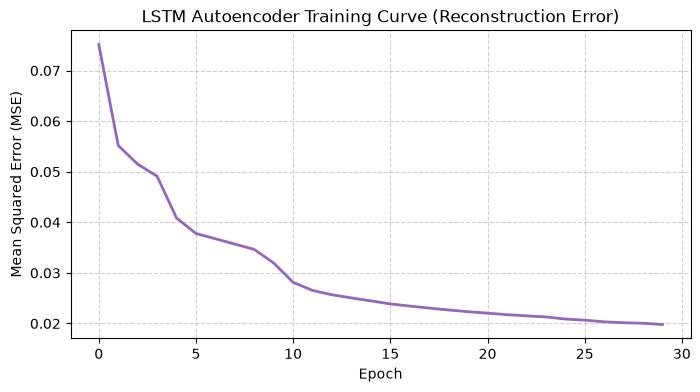

✅ Training complete! Saved 'telemetry_autoencoder.pth' to disk.


In [7]:
import torch.optim as optim

# 1. Define the Loss function and Optimizer
criterion = nn.MSELoss()
# Adam optimizer nudges the weights to minimize the loss
optimizer = optim.Adam(model.parameters(), lr=0.005) 

epochs = 30
loss_history = []

print("Starting Training Loop...")
model.train()

# 2. The Training Loop (Backpropagation Through Time)
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_data in dataloader:
        # Reset the gradients
        optimizer.zero_grad()
        
        # Forward pass: compress and reconstruct
        reconstruction = model(batch_data)
        
        # Calculate how badly the decoder failed
        loss = criterion(reconstruction, batch_data)
        
        # Backward pass: calculate gradients
        loss.backward()
        
        # Update the mathematical weights in the LSTM gates
        optimizer.step()
        
        epoch_loss += loss.item()
        
    avg_loss = epoch_loss / len(dataloader)
    loss_history.append(avg_loss)
    
    # Print progress every 5 epochs
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d}/{epochs} | MSE Loss: {avg_loss:.6f}")

# 3. Plot the learning curve
plt.figure(figsize=(8, 4))
plt.plot(loss_history, color='#9467bd', linewidth=2)
plt.title("LSTM Autoencoder Training Curve (Reconstruction Error)")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Save the weights AND normalization constants
checkpoint = {
    'model_state_dict': model.state_dict(),
    'min_val': min_val,  # Pulled from memory in Cell 2
    'max_val': max_val   # Pulled from memory in Cell 2
}
torch.save(checkpoint, 'telemetry_autoencoder.pth')
print("✅ Training complete! Saved 'telemetry_autoencoder.pth' to disk.")

In [17]:
import torch
import numpy as np
import torch.nn as nn

# 1. Load saved model and normalization constants
checkpoint = torch.load('telemetry_autoencoder.pth', weights_only=False)
min_val = checkpoint['min_val']
max_val = checkpoint['max_val']

if isinstance(min_val, torch.Tensor):
    min_val = min_val.numpy()
    max_val = max_val.numpy()

# 2. Re-initialize model
loaded_model = TelemetryLSTMAutoencoder(input_dim=4, hidden_dim=16, num_layers=2)
loaded_model.load_state_dict(checkpoint['model_state_dict'])
loaded_model.eval()

criterion = nn.MSELoss()

def evaluate_vitals(bpm, spo2, resp, age, label="Patient"):
    raw_input = np.array([bpm, spo2, resp, age], dtype=np.float32)
    
    # Normalize using training baselines
    normalized_input = (raw_input - min_val) / (max_val - min_val + 1e-8)
    
    # Broadcast to sequence of 10 steps: (1, 10, 4)
    sequence = np.tile(normalized_input, (10, 1))
    tensor_input = torch.tensor(sequence, dtype=torch.float32).unsqueeze(0)
    
    with torch.no_grad():
        reconstruction = loaded_model(tensor_input)
        loss = criterion(reconstruction, tensor_input).item()
        
    print(f"--- {label} ---")
    print(f"Vitals: HR {bpm} BPM | SpO2 {spo2}% | Resp {resp}/min | Age {age}")
    print(f"Anomaly Score (MSE): {loss:.5f}")
    if loss < 0.05:
        print("🟢 Verdict: NORMAL (Reconstructed cleanly)\n")
    else:
        print("🔴 Verdict: ANOMALY DETECTED! (High reconstruction penalty)\n")



In [18]:
evaluate_vitals(bpm=72.0, spo2=98.0, resp=15.0, age=30.0, label="Case 1: Healthy Baseline")
evaluate_vitals(bpm=175.0, spo2=82.0, resp=32.0, age=78.0, label="Case 2: Critical Anomaly")

--- Case 1: Healthy Baseline ---
Vitals: HR 72.0 BPM | SpO2 98.0% | Resp 15.0/min | Age 30.0
Anomaly Score (MSE): 0.01963
🟢 Verdict: NORMAL (Reconstructed cleanly)

--- Case 2: Critical Anomaly ---
Vitals: HR 175.0 BPM | SpO2 82.0% | Resp 32.0/min | Age 78.0
Anomaly Score (MSE): 5.64076
🔴 Verdict: ANOMALY DETECTED! (High reconstruction penalty)

